In [1]:
import kagglehub

path = kagglehub.dataset_download("uciml/forest-cover-type-dataset")

print("Path to dataset files:", path)

100%|██████████| 11.2M/11.2M [00:00<00:00, 44.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/uciml/forest-cover-type-dataset/versions/1


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print("Dataset path:",path)
print("Files:",os.listdir(path))

Dataset path: /root/.cache/kagglehub/datasets/uciml/forest-cover-type-dataset/versions/1
Files: ['covtype.csv']


In [3]:
csv_path = os.path.join(path,"covtype.csv")

df = pd.read_csv(csv_path)
df.shape

(581012, 55)

In [4]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null 

In [6]:
df.isnull().sum()

,0
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,...,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226,...,0.090392,0.077716,0.002773,0.003255,0.000205,0.000513,0.026803,0.023762,0.015060,2.051471
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210,...,0.286743,0.267725,0.052584,0.056957,0.014310,0.022641,0.161508,0.152307,0.121791,1.396504
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


In [9]:
df.nunique().sort_values()

,0
Wilderness_Area3,2
Wilderness_Area4,2
Soil_Type2,2
Soil_Type1,2
Wilderness_Area1,2
Wilderness_Area2,2
Soil_Type12,2
Soil_Type11,2
Soil_Type10,2
Soil_Type9,2


In [10]:
df["Cover_Type"].value_counts().sort_index()

,count
Cover_Type,
1,211840
2,283301
3,35754
4,2747
5,9493
6,17367
7,20510


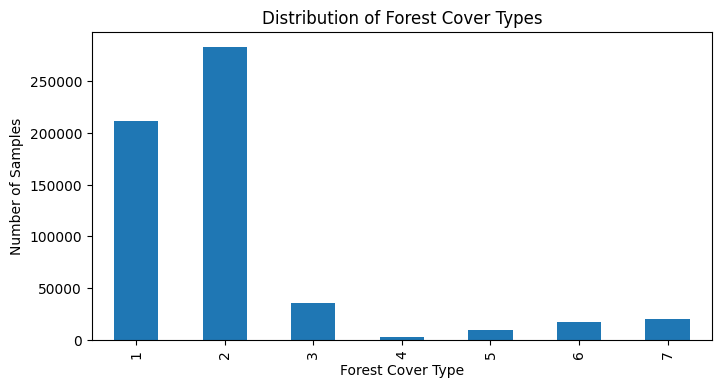

In [11]:
df["Cover_Type"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.xlabel("Forest Cover Type")
plt.ylabel("Number of Samples")
plt.title("Distribution of Forest Cover Types")
plt.show()

In [12]:
X = df.drop('Cover_Type',axis=1)
y = df['Cover_Type']

print("Feature shpe:",X.shape)
print("Target shape",y.shape)

Feature shpe: (581012, 54)
Target shape (581012,)


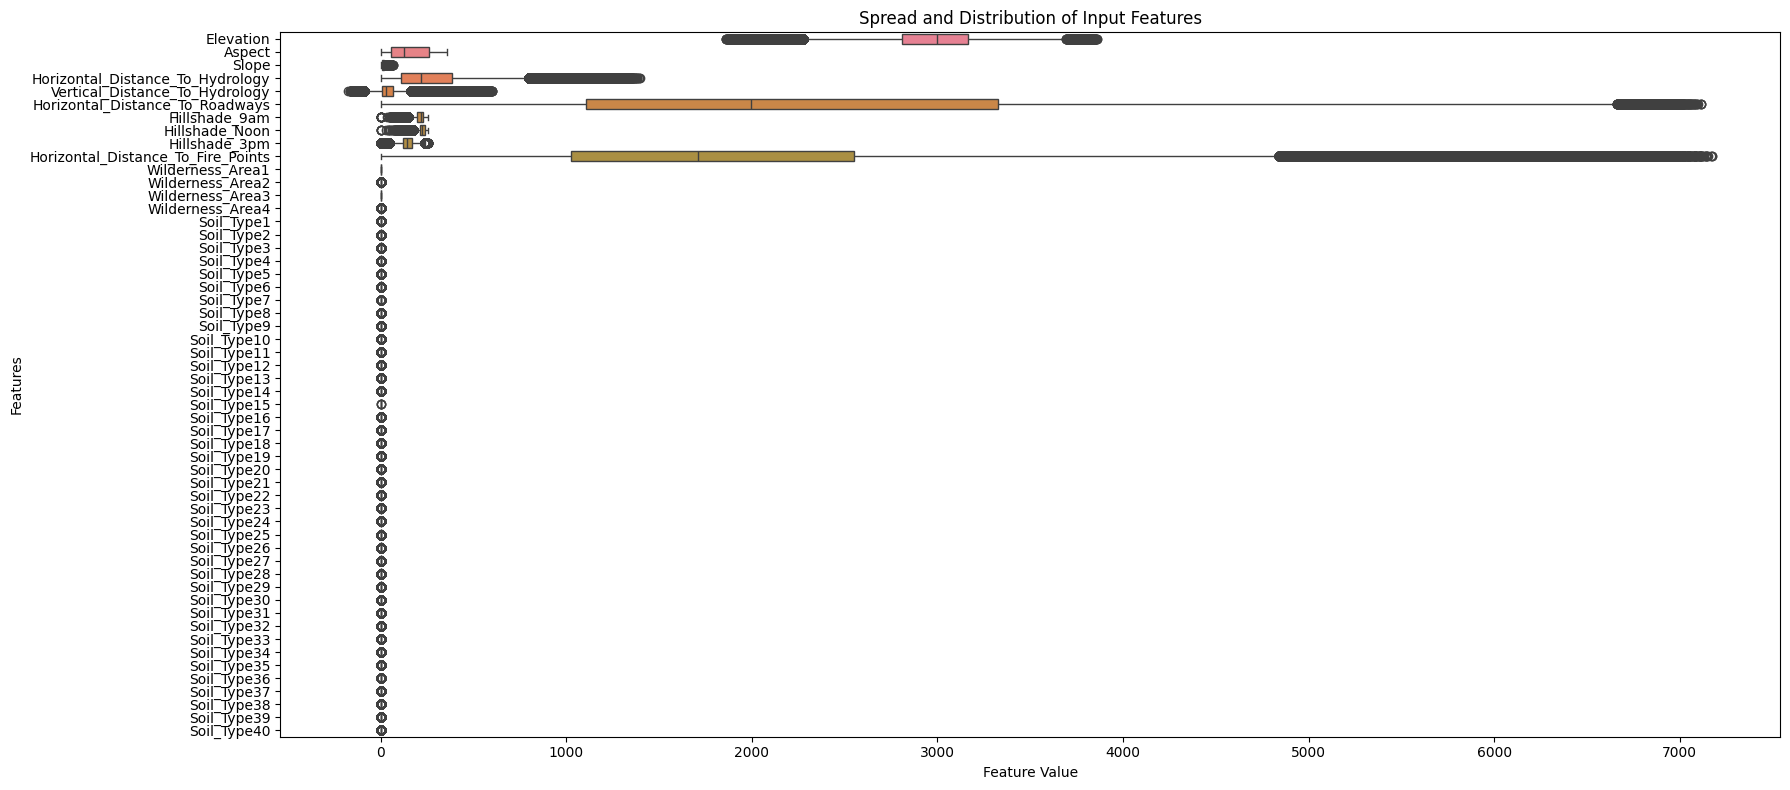

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns


# Plot boxplots for all input features
plt.figure(figsize=(18, 8))
sns.boxplot(data=X, orient="h")

plt.title("Spread and Distribution of Input Features")
plt.xlabel("Feature Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [14]:
 from sklearn.model_selection import train_test_split

# Separating features and target
X = df.drop(columns=["Cover_Type"])
y = df["Cover_Type"]

# 70% training, 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Splitting remaining data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (406708, 54) (406708,)
Validation: (87152, 54) (87152,)
Testing: (87152, 54) (87152,)


In [15]:
from sklearn.preprocessing import StandardScaler

# Continuous numerical features
continuous_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

scaler = StandardScaler()

X_train[continuous_cols]=scaler.fit_transform(
    X_train[continuous_cols]
)

X_val[continuous_cols]=scaler.transform(
    X_val[continuous_cols]
)

X_test[continuous_cols]=scaler.transform(
    X_test[continuous_cols]
)








In [16]:
X_test.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
253235,1.290439,0.502331,-0.682334,1.754576,0.815587,0.901050,0.032530,1.299059,0.769388,0.303227,...,0,0,0,0,0,0,0,0,0,0
301775,-1.611918,-0.908938,-0.682334,-0.270103,0.198108,-0.956924,0.480859,-0.117231,-0.327625,-1.170663,...,0,0,0,0,0,0,0,0,0,0
108642,0.112361,0.895343,-1.082982,0.789322,0.489695,1.945518,-0.228996,1.046150,0.873865,-0.110431,...,0,0,0,0,0,0,0,0,0,0
68110,1.015554,-0.632044,-0.548784,-0.138264,-0.127784,0.419876,0.854468,-0.016067,-0.614938,2.141618,...,0,0,0,0,0,0,0,0,1,0
450758,0.230169,1.592045,0.118962,-0.562034,-0.076327,-0.674635,-1.013573,-0.218394,0.795507,-0.494595,...,0,1,0,0,0,0,0,0,0,0


In [17]:
X_val.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
261080,-2.143838,0.993596,0.786709,0.436180,-0.367915,-1.392546,-1.798150,0.995569,1.918640,-0.937745,...,0,0,0,0,0,0,0,0,0,0
381355,0.615722,0.439807,-0.949433,-0.364275,-0.367915,-0.833101,0.144612,1.147314,0.612672,-0.443171,...,0,0,0,0,0,0,0,0,0,0
249325,-2.393733,0.940003,0.519610,-0.868090,-0.933937,-1.185321,-1.499264,1.197896,1.788043,-1.173688,...,0,0,0,0,0,0,0,0,0,0
189619,0.390816,-0.676704,-0.148136,-1.070558,-0.693806,1.003700,0.929189,-0.420721,-0.928371,-1.099578,...,0,0,0,0,0,0,0,0,0,0
53795,-0.180374,-0.551655,-0.415235,-0.985804,-0.590893,0.901050,0.966550,-0.016067,-0.719416,2.347313,...,0,0,0,0,0,0,0,0,0,0


In [18]:
X_train.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
244336,-0.487388,-1.123308,1.988653,-0.505531,-0.007719,-0.770228,-0.527882,-2.949810,-1.450758,-0.175466,...,0,0,0,0,0,0,0,0,0,0
518278,1.297579,1.600978,0.118962,1.641571,0.506847,-0.939601,-1.013573,-0.268976,0.769388,-0.608785,...,0,0,0,0,0,0,0,0,0,0
151614,-0.490958,1.699230,-0.014587,-0.759793,-0.453676,0.049051,-0.752047,-0.319558,0.508194,-0.035564,...,0,0,0,0,0,0,0,0,0,0
85676,-0.430269,-0.024662,-0.949433,-1.268318,-0.796719,1.058875,0.630303,0.894405,0.038046,1.046599,...,0,0,0,0,0,0,0,0,0,0
419952,0.758519,0.493399,0.920258,-0.166515,0.575456,0.515469,-0.527882,1.551968,1.082820,-0.757006,...,0,0,1,0,0,0,0,0,0,0


In [19]:
X_train.shape

(406708, 54)

In [20]:
y_train_tf = y_train - 1
y_val_tf = y_val - 1
y_test_tf = y_test -1

print("Unique target labels:",sorted(y_train_tf.unique()))

'''We subtract 1 because TensorFlow classification models
 commonly use class indices starting at 0'''

Unique target labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


'We subtract 1 because TensorFlow classification models\n commonly use class indices starting at 0'

In [21]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(7, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop =EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train_tf,
    validation_data=(X_val,y_val_tf),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7618 - loss: 0.5650 - val_accuracy: 0.7983 - val_loss: 0.4793
Epoch 2/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8126 - loss: 0.4426 - val_accuracy: 0.8268 - val_loss: 0.4157
Epoch 3/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8325 - loss: 0.3991 - val_accuracy: 0.8387 - val_loss: 0.3844
Epoch 4/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8450 - loss: 0.3710 - val_accuracy: 0.8515 - val_loss: 0.3597
Epoch 5/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8544 - loss: 0.3510 - val_accuracy: 0.8580 - val_loss: 0.3465
Epoch 6/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8603 - loss: 0.3361 - val_accuracy: 0.8570 - val_loss: 0.3437
Epoch 7/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8663 - loss: 0.3221 - val_accuracy: 0.8663 - val_loss: 0.3268
Epoch 8/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8709 - loss:

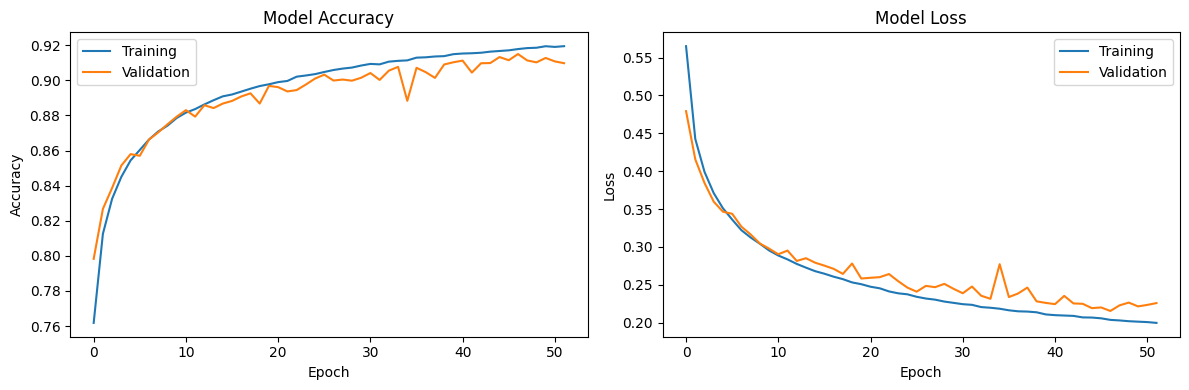

In [23]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Test Loss: 0.2154
Test Accuracy: 91.6101%

Classification Report:
              precision    recall  f1-score   support

Cover Type 1     0.9111    0.9158    0.9134     31776
Cover Type 2     0.9259    0.9321    0.9290     42496
Cover Type 3     0.8939    0.9271    0.9102      5363
Cover Type 4     0.7981    0.8155    0.8067       412
Cover Type 5     0.8250    0.7549    0.7884      1424
Cover Type 6     0.8778    0.7608    0.8151      2605
Cover Type 7     0.9580    0.8982    0.9272      3076

    accuracy                         0.9161     87152
   macro avg     0.8843    0.8578    0.8700     87152
weighted avg     0.9160    0.9161    0.9158     87152



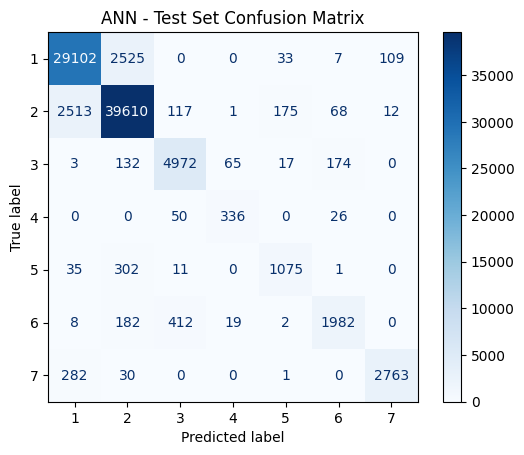

In [24]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Evaluate on the untouched test set
test_loss, test_accuracy = model.evaluate(
    X_test, y_test_tf, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# Generate predictions
test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

# Detailed metrics for all seven classes
print("\nClassification Report:")
print(classification_report(
    y_test_tf,
    y_pred,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test_tf, y_pred, labels=np.arange(7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(1, 8)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ANN - Test Set Confusion Matrix")
plt.show()


In [27]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

#calculate class weight using training labels only
classes = np.unique(y_train_tf)
class_weights = compute_class_weight(
              class_weight="balanced",
              classes=classes,
              y=y_train_tf

)

class_weight = dict(zip(classes, class_weights))

print("Class weight:")
print(class_weights)

#creating a fresh ann
ann_weighted = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(7, activation="softmax")
])

ann_weighted.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_weighted = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_weighted = ann_weighted.fit(
    X_train, y_train_tf,
    validation_data=(X_val,y_val_tf),
    epochs=100,
    batch_size=256,
    class_weight=class_weight,
    callbacks=[early_stopping_weighted],
    verbose=1
)

Class weight:
[ 0.39181284  0.29298141  2.3214457  30.21380284  8.74358809  4.7792336
  4.04688604]
Epoch 1/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.6252 - loss: 0.6466 - val_accuracy: 0.6597 - val_loss: 0.7829
Epoch 2/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6883 - loss: 0.5011 - val_accuracy: 0.7069 - val_loss: 0.6707
Epoch 3/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7165 - loss: 0.4501 - val_accuracy: 0.7397 - val_loss: 0.5894
Epoch 4/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7384 - loss: 0.4123 - val_accuracy: 0.7568 - val_loss: 0.5611
Epoch 5/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7540 - loss: 0.3871 - val_accuracy: 0.7719 - val_loss: 0.5349
Epoch 6/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7670 - loss: 0.3644 - val_accuracy: 0.7578 - val_loss: 0.5694
Epoch 7/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7761 - loss: 0.3489 - val_accuracy: 0.7739 -

In [29]:
y_val_pred_weighted = np.argmax(
    ann_weighted.predict(X_val,verbose=0),
    axis=1
)

print(classification_report(
    y_val_tf,
    y_val_pred_weighted,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1,8)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

Cover Type 1     0.8642    0.8295    0.8465     31776
Cover Type 2     0.8889    0.8414    0.8645     42495
Cover Type 3     0.8824    0.8423    0.8619      5363
Cover Type 4     0.6055    0.9684    0.7451       412
Cover Type 5     0.4510    0.9565    0.6130      1424
Cover Type 6     0.6420    0.9113    0.7533      2605
Cover Type 7     0.7673    0.9805    0.8609      3077

    accuracy                         0.8466     87152
   macro avg     0.7287    0.9043    0.7922     87152
weighted avg     0.8593    0.8466    0.8496     87152



In [31]:
classes = np.unique(y_train_tf)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_tf
)

# now i am softening the weights using square root
mild_weight = {
    int(cls): float(np.sqrt(weight))
    for cls, weight in zip(classes, balanced_weights)
}

print("Milder class weight:", mild_weight)

# Fresh model with the same architecture

ann_mild = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(7,activation="softmax")
])

ann_mild.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_mild = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_mild = ann_mild.fit(
    X_train,
    y_train_tf,
    validation_data=(X_val,y_val_tf),
    epochs=50,
    batch_size=256,
    class_weight=mild_weight,
    callbacks=[early_stop_mild],
    verbose=1
)

Milder class weight: {0: 0.6259495530487726, 1: 0.5412775694376726, 2: 1.5236291199327985, 3: 5.49670836390542, 4: 2.9569558822991397, 5: 2.1861458319413805, 6: 2.0116873610645993}
Epoch 1/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7307 - loss: 0.5316 - val_accuracy: 0.7705 - val_loss: 0.5259
Epoch 2/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7810 - loss: 0.4157 - val_accuracy: 0.7899 - val_loss: 0.4890
Epoch 3/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8043 - loss: 0.3738 - val_accuracy: 0.7965 - val_loss: 0.4752
Epoch 4/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8199 - loss: 0.3444 - val_accuracy: 0.8306 - val_loss: 0.3998
Epoch 5/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8305 - loss: 0.3248 - val_accuracy: 0.8270 - val_loss: 0.4145
Epoch 6/50
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8395 - loss: 0.3082 - val_accuracy: 0.8365 - val_loss: 0.3909
Epoch 7/50
1589/1589 ━━━━━━━━━━━━━━━━

In [32]:

y_val_pred_mild = np.argmax(
    ann_mild.predict(X_val, verbose=0),
    axis=1
)

print(classification_report(
    y_val_tf,
    y_val_pred_mild,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

Cover Type 1     0.9208    0.8530    0.8856     31776
Cover Type 2     0.8978    0.9226    0.9100     42495
Cover Type 3     0.8644    0.9161    0.8895      5363
Cover Type 4     0.7667    0.9175    0.8354       412
Cover Type 5     0.7092    0.7963    0.7502      1424
Cover Type 6     0.7939    0.8472    0.8197      2605
Cover Type 7     0.8484    0.9623    0.9018      3077

    accuracy                         0.8939     87152
   macro avg     0.8287    0.8879    0.8560     87152
weighted avg     0.8956    0.8939    0.8939     87152



In [35]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

ann_tuned = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(256, activation="relu"),
    Dropout(0.2),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(64, activation="relu"),

    Dense(7, activation="softmax")
])

ann_tuned.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_tuned = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_tuned = ann_tuned.fit(
    X_train,
    y_train_tf,
    validation_data=(X_val, y_val_tf),
    epochs=60,
    batch_size=256,
    callbacks=[early_stop_tuned, reduce_lr],
    verbose=1
)

Epoch 1/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.7477 - loss: 0.5921 - val_accuracy: 0.7960 - val_loss: 0.4752 - learning_rate: 0.0010
Epoch 2/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.7954 - loss: 0.4763 - val_accuracy: 0.8256 - val_loss: 0.4149 - learning_rate: 0.0010
Epoch 3/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8141 - loss: 0.4358 - val_accuracy: 0.8444 - val_loss: 0.3783 - learning_rate: 0.0010
Epoch 4/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.8261 - loss: 0.4109 - val_accuracy: 0.8553 - val_loss: 0.3509 - learning_rate: 0.0010
Epoch 5/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.8343 - loss: 0.3914 - val_accuracy: 0.8615 - val_loss: 0.3358 - learning_rate: 0.0010
Epoch 6/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.8414 - loss: 0.3771 - val_accuracy: 0.8683 - val_loss: 0.3247 - learning_rate: 0.0010
Epoch 7/60
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.

In [36]:

from sklearn.metrics import classification_report
import numpy as np

y_val_pred_tuned = np.argmax(
    ann_tuned.predict(X_val, verbose=0),
    axis=1
)

print(classification_report(
    y_val_tf,
    y_val_pred_tuned,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

Cover Type 1     0.9324    0.9150    0.9236     31776
Cover Type 2     0.9327    0.9437    0.9382     42495
Cover Type 3     0.9316    0.9373    0.9345      5363
Cover Type 4     0.8976    0.8301    0.8625       412
Cover Type 5     0.8097    0.8069    0.8083      1424
Cover Type 6     0.8668    0.8967    0.8815      2605
Cover Type 7     0.9367    0.9386    0.9377      3077

    accuracy                         0.9285     87152
   macro avg     0.9011    0.8955    0.8980     87152
weighted avg     0.9285    0.9285    0.9284     87152



In [37]:

from sklearn.metrics import accuracy_score, f1_score

y_val_pred_tuned = np.argmax(
    ann_tuned.predict(X_val, verbose=0),
    axis=1
)

print("Validation accuracy:",
      f"{accuracy_score(y_val_tf, y_val_pred_tuned):.4%}")

print("Validation macro F1:",
      f"{f1_score(y_val_tf, y_val_pred_tuned, average='macro'):.4%}")


Validation accuracy: 92.8470%
Validation macro F1: 89.8036%


In [38]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Original ANN predictions
y_val_pred_original = np.argmax(
    model.predict(X_val, verbose=0),
    axis=1
)

# Tuned ANN predictions
y_val_pred_tuned = np.argmax(
    ann_tuned.predict(X_val, verbose=0),
    axis=1
)

# Compare both on the same validation set
comparison = pd.DataFrame({
    "Model": ["Original ANN", "Tuned ANN"],
    "Validation Accuracy": [
        accuracy_score(y_val_tf, y_val_pred_original),
        accuracy_score(y_val_tf, y_val_pred_tuned)
    ],
    "Macro F1": [
        f1_score(y_val_tf, y_val_pred_original, average="macro"),
        f1_score(y_val_tf, y_val_pred_tuned, average="macro")
    ]
})

print(comparison.to_string(index=False))


       Model  Validation Accuracy  Macro F1
Original ANN             0.915011  0.866133
   Tuned ANN             0.928470  0.898036


Test Loss: 0.1827
Test Accuracy: 92.8653%

Classification Report:
              precision    recall  f1-score   support

Cover Type 1     0.9323    0.9159    0.9240     31776
Cover Type 2     0.9333    0.9436    0.9384     42496
Cover Type 3     0.9355    0.9359    0.9357      5363
Cover Type 4     0.8731    0.8180    0.8446       412
Cover Type 5     0.7887    0.8020    0.7953      1424
Cover Type 6     0.8713    0.8967    0.8838      2605
Cover Type 7     0.9381    0.9418    0.9400      3076

    accuracy                         0.9287     87152
   macro avg     0.8960    0.8934    0.8945     87152
weighted avg     0.9287    0.9287    0.9286     87152



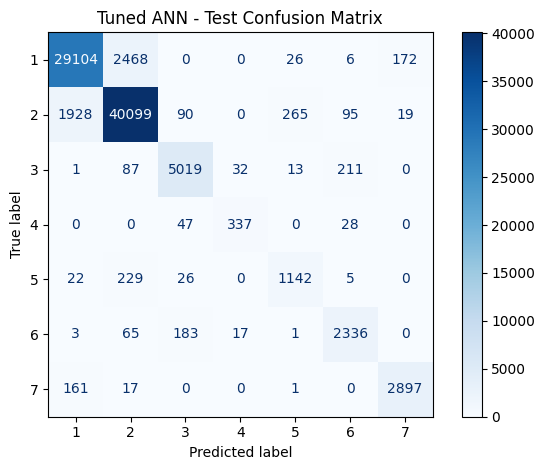

In [39]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# 1. Evaluate test loss and accuracy
test_loss, test_accuracy = ann_tuned.evaluate(
    X_test,
    y_test_tf,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# 2. Generate predictions
test_probs_tuned = ann_tuned.predict(X_test, verbose=0)
y_test_pred_tuned = np.argmax(test_probs_tuned, axis=1)

# 3. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_tf,
    y_test_pred_tuned,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    digits=4,
    zero_division=0
))

# 4. Confusion matrix
cm = confusion_matrix(
    y_test_tf,
    y_test_pred_tuned,
    labels=np.arange(7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(1, 8)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned ANN - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [40]:

from google.colab import drive
drive.mount('/content/drive')

import os
import joblib

# Create a folder in Google Drive
save_dir = "/content/drive/MyDrive/Forest_Cover_Project"
os.makedirs(save_dir, exist_ok=True)

# 1. Save your best trained ANN
ann_tuned.save(
    os.path.join(save_dir, "ann_tuned.keras")
)

# 2. Save the fitted feature scaler
joblib.dump(
    scaler,
    os.path.join(save_dir, "scaler.pkl")
)

# 3. Save your dataset splits and labels
joblib.dump(
    {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "y_train_tf": y_train_tf,
        "y_val_tf": y_val_tf,
        "y_test_tf": y_test_tf,
        "continuous_cols": continuous_cols
    },
    os.path.join(save_dir, "data_splits.pkl"),
    compress=3
)

print("All project files saved to:", save_dir)
print("Saved model, scaler and dataset splits.")


Mounted at /content/drive
All project files saved to: /content/drive/MyDrive/Forest_Cover_Project
Saved model, scaler and dataset splits.
